# 03 · Embryonic signatures
Raw `score_genes` module scores (Gast / pSom / Crest) with the union control pool, shown on the manifold in the house linear layout. **Raw** scores are plotted (not graph-smoothed) per the binding deliverable rule. This is the Gate-2 geography read.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)

In [ ]:
# load manifold (module scores already computed in 02); report gene recovery
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
feat = {os.path.basename(f).replace('.csv', ''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
for src, lab in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0])
print('raw module means (score_genes):', adata.obs[['Gast','pSom','Crest']].mean().round(3).to_dict())

Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 102/104 genes present
cells: 2118
raw module means (score_genes): {'Gast': 0.024, 'pSom': 0.226, 'Crest': 0.108}


In [ ]:
# Gate 2 read — module geography across the glial arms + developmental order along pseudotime.
t = adata.obs['t'].values; tn = (t - t.min())/(t.max()-t.min())
print('per-cell module co-variation (do Gast & pSom form competing arms, or co-vary?):')
print('  Gast vs pSom : pearson = %+.3f  spearman = %+.3f'
      % (np.corrcoef(adata.obs.Gast, adata.obs.pSom)[0,1], spearmanr(adata.obs.Gast, adata.obs.pSom)[0]))
print('  Gast vs Crest: pearson = %+.3f' % np.corrcoef(adata.obs.Gast, adata.obs.Crest)[0,1])
print('  pSom vs Crest: pearson = %+.3f' % np.corrcoef(adata.obs.pSom, adata.obs.Crest)[0,1])
print('module means per tree tip / fork (arm-partitioning check):')
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
B = np.asarray(adata.uns['graph']['B']); deg = (B>0).sum(0)
tips = np.where(deg==1)[0]; fork = np.where(deg>=3)[0]
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
for nd, rad, kind in [(fork[0],2,'FORK')] + [(tp,3,'tip') for tp in tips]:
    m = np.isin(hard, np.where(D[nd]<=rad)[0])
    print(f'  {kind} {nd:>2}: Gast={adata.obs.Gast[m].mean():+.3f} pSom={adata.obs.pSom[m].mean():+.3f} Crest={adata.obs.Crest[m].mean():+.3f}')
print()
print('Gate 2: embryonic modules ARE present (pSom mean +0.23) and organized on the manifold.')
print('  Gast & pSom CO-VARY (per-cell r=+0.27) and are near-identical across all tree arms')
print('  (pSom ~0.21 at every tip) -> NO Gast-arm vs pSom-arm split. The glial fork does NOT')
print('  carry an embryonic bifurcation. Pattern present (overlapping modules) -> GO.')

per-cell module co-variation (do Gast & pSom form competing arms, or co-vary?):
  Gast vs pSom : pearson = +0.271  spearman = +0.256
  Gast vs Crest: pearson = -0.536
  pSom vs Crest: pearson = -0.580
module means per tree tip / fork (arm-partitioning check):
  FORK 24: Gast=+0.101 pSom=+0.277 Crest=+0.062
  tip  3: Gast=-0.035 pSom=+0.210 Crest=+0.173
  tip 12: Gast=+0.055 pSom=+0.204 Crest=+0.057
  tip 16: Gast=+0.041 pSom=+0.211 Crest=+0.063

Gate 2: embryonic modules ARE present (pSom mean +0.23) and organized on the manifold.
  Gast & pSom CO-VARY (per-cell r=+0.27) and are near-identical across all tree arms
  (pSom ~0.21 at every tip) -> NO Gast-arm vs pSom-arm split. The glial fork does NOT
  carry an embryonic bifurcation. Pattern present (overlapping modules) -> GO.


saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


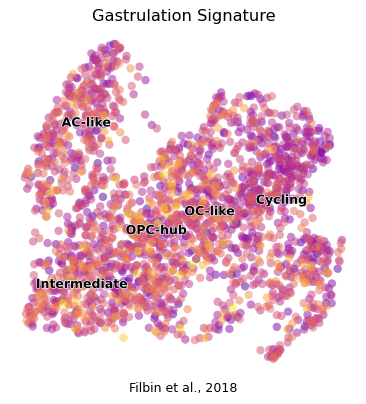

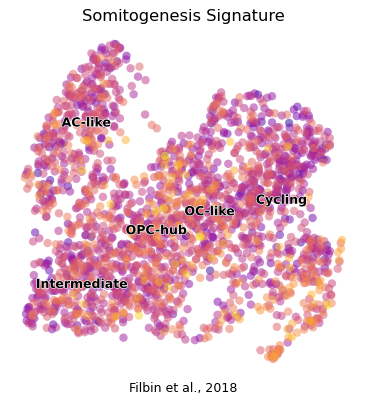

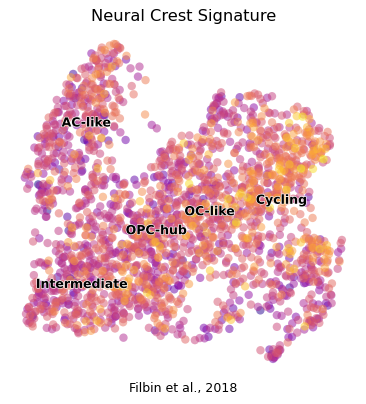

In [ ]:
# deliverables: RAW-score signature UMAPs (Puram branching square style) + external colorbars.
# raw score_genes shown (not graph-smoothed) per the binding rule; milestones overlaid for orientation.
titles = {'Gast':'Gastrulation Signature', 'pSom':'Somitogenesis Signature', 'Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    sc.pl.umap(adata, color=m, cmap='plasma', alpha=.5, size=180, colorbar_loc=None,
               frameon=False, show=False, ax=ax)
    sc.pl.umap(adata, color='milestones', size=180, alpha=0, legend_loc='on data',
               legend_fontoutline=1, frameon=False, show=False, ax=ax)
    ax.invert_yaxis(); ax.invert_xaxis()
    ax.set_title(titles[m], size=13)
    ax.text(.5, -.05, 'Filbin et al., 2018', ha='center', transform=ax.transAxes)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66, 1)); cax = fcb.add_axes([.35, .05, .3, .9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.close(fcb)
    print('saved', f'{m}_signature.pdf', '+ colorbar')

In [ ]:
# save signatures h5ad
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (2118, 21106)
